# Task4 — Strong Augmentation × Class Imbalance

Run All บน project นี้: โหลด baseline ที่ทำไว้ → preview → ฝึก 2 สูตร × 5 folds → เทียบ OOF → refit เฉพาะสูตรที่ผ่าน → predict → รวม submission โดยคง Task5 รุ่น **0.79963**.

ไม่ได้รับประกันคะแนนสูงขึ้น. สูตรเดิมมี class weights อยู่แล้ว. รอบนี้แยกผล augmentation และ sampling: heavy + weighted CE กับ heavy + balanced sampler/unweighted CE. ใช้ ResNet18, 18 epochs และ folds เดิมเพื่อให้เทียบได้. **10 fits = 180 fold epochs** บวก full refit 18 epochs หากเลือกสูตรใหม่และเวลา TTA; บน Mac อาจใช้หลายชั่วโมง. ไม่รันสูตร EfficientNet/ConvNeXt เพิ่มอัตโนมัติ.

เซฟทุก epoch; กลับมา Run All ด้วย settings เดิมเพื่อ resume. กลาง epoch จะเริ่ม epoch นั้นใหม่. ห้ามเปลี่ยนสูตรใน output เดิม. Notebook นี้ใช้ไฟล์ใน project ไม่ใช่ standalone Colab bundle.

## 1. Setup & configuration

In [1]:
from pathlib import Path
import sys, json, hashlib, csv, gc
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from dataclasses import asdict
from IPython.display import display
ROOT=next(p for base in (Path.cwd(),*Path.cwd().parents) for p in (base,base/'CPE342-Kaggle') if (p/'Task4/models/image_heavy_followup.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from Task4.models import image_heavy_followup as training
from Task4.models.image_heavy_augmentation import HeavyAugmentation
from Task4.models.image_audit import make_folds
RUN_NAME='heavy_balance_v1'
BATCH_SIZE=32
NUM_WORKERS=0
RUN_TRAINING=True
RUN_FULL_REFIT=True
MIN_MEAN_GAIN=.001
ACTIVE=list(training.RECIPES)
RAW=ROOT/'Task4/data/raw'
OLD=ROOT/'Task4/models/results/gpu_followup_v1'
AUDIT=ROOT/'Task4/data/audit/followup_v2'
OUT=ROOT/'Task4/models/results'/RUN_NAME
BASE_SUBMISSION=ROOT/'submission/kaggle_t12345_t1_slow800_bagging_v4_t3_conditional_quantile_v1_t4_resnet18_cosine18_tta_v1_t5_directional_gap_cut_v1.csv'
BASE_SUBMISSION_SHA='6e5ba45b87a8e83a53d762f474991c2ffa7a6be43ba0a276e8a97a6e365e0fe2'
BASELINE='resnet18_cosine18__tta'
sha=lambda p:hashlib.sha256(Path(p).read_bytes()).hexdigest()
import os
os.environ['TORCH_HOME']=str(ROOT/'Task4/cache/torch')
torch.set_num_threads(4)
print('Device:',training.get_device(),'| output:',OUT)
if training.get_device().type=='cpu':raise RuntimeError('ไม่พบ CUDA/MPS: ตรวจ environment ก่อนรันงานหลายชั่วโมง')
assert sha(BASE_SUBMISSION)==BASE_SUBMISSION_SHA


Device: mps | output: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/Task4/models/results/heavy_balance_v1


## 2. Train-only metadata, class balance และ paired folds

Validation ใช้ภาพจริง ไม่มี oversampling หรือ heavy augmentation. ใช้ near-duplicate groups เดิม และตรวจ identity กับ baseline ก่อนเริ่ม. Test ไม่เข้าการฝึกหรือเลือกสูตร.

In [2]:
groups=pd.read_parquet(AUDIT/'train_groups.parquet')
train=pd.read_csv(RAW/'train.csv')
assert len(groups)==len(train)
assert all(np.array_equal(groups[c].to_numpy(),train[c].to_numpy()) for c in ['id','file_name','label'])
folds=make_folds(groups,mode='near',n_splits=5,seed=42)
old_settings=json.loads((OLD/'settings.json').read_text())
fold_hash=hashlib.sha256(b''.join(v.astype('int64').tobytes() for _,v in folds)).hexdigest()
assert fold_hash==old_settings['fold_hash']
for relative,digest in old_settings['helper_sha256'].items():assert sha(ROOT/relative)==digest, f'Baseline helper differs: {relative}'
base_parts=[]
for k,(fit,valid) in enumerate(folds,1):
    frame=pd.read_parquet(OLD/'resnet18_cosine18'/f'fold{k}'/'oof.parquet')
    assert np.array_equal(frame.row_index,valid)
    assert np.array_equal(frame.id,groups.iloc[valid].id)
    assert np.array_equal(frame.true,groups.iloc[valid].label.astype(int))
    assert not np.intersect1d(fit,valid).size
    base_parts.append(frame)
base=pd.concat(base_parts).sort_values('row_index').reset_index(drop=True)
assert len(base)==len(train) and base.row_index.is_unique
counts=train.label.value_counts().sort_index()
display(pd.DataFrame({'class':training.CLASS_NAMES,'train_count':counts.to_numpy(),'fraction':counts.to_numpy()/len(train),'inverse_frequency_weight':len(train)/(5*counts.to_numpy())}))
print('Imbalance ratio:',counts.max()/counts.min())
settings={'recipes':{k:asdict(training.RECIPES[k]) for k in ACTIVE},'batch_size':BATCH_SIZE,'workers':NUM_WORKERS,'fold_hash':fold_hash,
 'train_manifest_sha256':sha(RAW/'train.csv'),'base_submission_sha256':BASE_SUBMISSION_SHA,
 'baseline_oof_sha256':[sha(OLD/'resnet18_cosine18'/f'fold{k}'/'oof.parquet') for k in range(1,6)],
 'sources':{p:sha(ROOT/'Task4/models'/p) for p in ['image_heavy_followup.py','image_heavy_augmentation.py','image_training.py']},
 'torch':str(torch.__version__),'device':str(training.get_device()),'minimum_gain':MIN_MEAN_GAIN,'tta':list(training.TTA_VIEWS)}
OUT.mkdir(parents=True,exist_ok=True)
if (OUT/'settings.json').exists():assert json.loads((OUT/'settings.json').read_text())==settings,'เปลี่ยน RUN_NAME เมื่อ configuration เปลี่ยน'
else:
    assert not any(OUT.iterdir()),'Output มีไฟล์แต่ไม่มี settings'
    (OUT/'settings.json').write_text(json.dumps(settings,indent=2))


,class,train_count,fraction,inverse_frequency_weight
0,7-11k,12429,0.393996,0.507619
1,fiveN,4407,0.139701,1.431631
2,freefried,5596,0.177392,1.127448
3,pube,5926,0.187853,1.064664
4,roblock,3188,0.101059,1.979046


Imbalance ratio: 3.898682559598494


## 3. Preview augmentation ก่อนฝึก

85% ของการเปิดภาพสุ่ม 3 operations จาก 10 ชนิด: rotation (บางครั้ง ±180°), affine/scale/shear/translation, perspective, color jitter, blur, JPEG compression, downsample, sharpness, autocontrast และ grayscale. Noise 35%, small erasing 15% เพิ่มแยกกัน. เก็บ aspect resize/padding เดิม ไม่ทำ flip เพราะ HUD/text อาจสลับด้าน. สุ่มใหม่ online แต่ละ epoch ไม่สร้างภาพซ้ำบนดิสก์. ภาพบางส่วนยังอาจเสีย semantic cues จึงต้องดู OOF เทียบจริง.

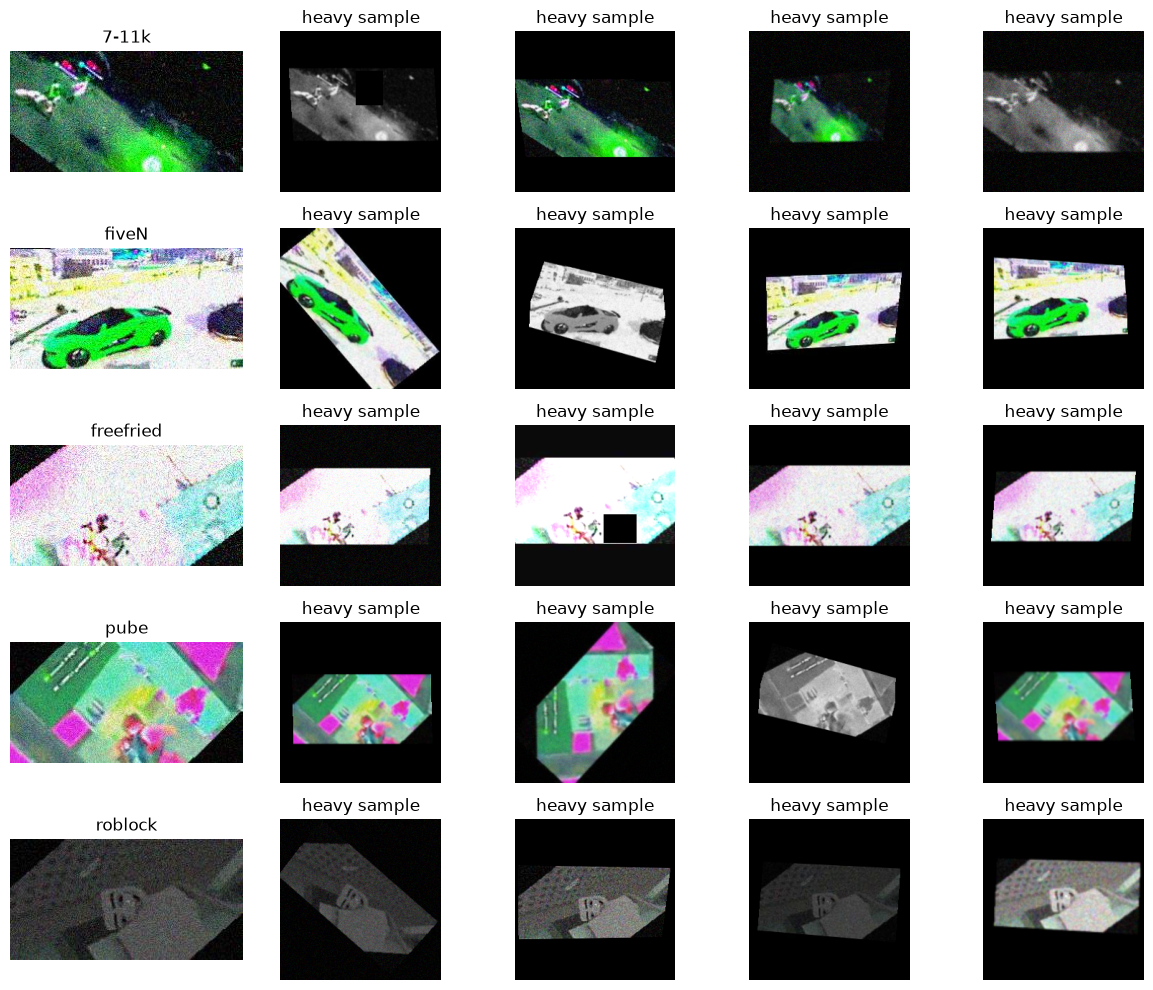

In [3]:
training.seed_everything(123)
fig,axes=plt.subplots(5,5,figsize=(12,10))
aug=HeavyAugmentation()
for label in range(5):
    item=train.loc[train.label.eq(label)].iloc[0]
    with Image.open(RAW/'train'/item.file_name) as f:image=f.convert('RGB')
    axes[label,0].imshow(image);axes[label,0].set_title(training.CLASS_NAMES[label])
    for j in range(1,5):
        tensor=aug(image)
        view=(tensor*torch.tensor(training.STD)[:,None,None]+torch.tensor(training.MEAN)[:,None,None]).clamp(0,1)
        axes[label,j].imshow(view.permute(1,2,0));axes[label,j].set_title('heavy sample')
for ax in axes.flat:ax.axis('off')
plt.tight_layout();fig.savefig(OUT/'augmentation_preview.png',dpi=120);plt.show()


## 4. Train & resume — 2 recipes × 5 folds

Weighted loss ใช้ fold-local inverse class frequency. Balanced sampler สุ่มพร้อมคืนกลับ N ครั้งต่อ epoch ให้แต่ละ class มี expected share 20% และใช้ unweighted CE จึงไม่ชดเชยซ้ำ. Training seed ถูก reset ต่อ epoch เพื่อ replay เมื่อหยุดกลางรอบ. model.pt/resume.pt และ optimizer/scaler/scheduler state เก็บในแต่ละ fold. ห้ามรันพร้อมกันสอง kernel ลง output เดียวกัน.

In [4]:
oof={}
for name in ACTIVE:
    parts=[]
    for k in range(1,6):
        print('Training',name,'fold',k,flush=True)
        if not RUN_TRAINING and not (OUT/name/f'fold{k}'/'model.pt').exists():
            raise FileNotFoundError(f'ยังไม่มี model: {name} fold{k}; เปิด RUN_TRAINING')
        frame=training.run_fold(RAW,groups,folds,name,k,OUT,BATCH_SIZE,NUM_WORKERS)
        parts.append(frame)
        print(training.score_probabilities(frame.true,training.probabilities(frame,'tta')),flush=True)
        gc.collect()
    oof[name]=pd.concat(parts).sort_values('row_index').reset_index(drop=True)
    assert oof[name].id.tolist()==base.id.tolist()
    oof[name].to_parquet(OUT/f'{name}_oof.parquet',index=False)


Training heavy_weighted18 fold 1
fold1 epoch 1 / 18 loss 0.66818 seconds 143.5
fold1 epoch 2 / 18 loss 0.39524 seconds 138.1
fold1 epoch 3 / 18 loss 0.28357 seconds 138.2
fold1 epoch 4 / 18 loss 0.23428 seconds 138.4
fold1 epoch 5 / 18 loss 0.20089 seconds 138.2
fold1 epoch 6 / 18 loss 0.1725 seconds 138.1
fold1 epoch 7 / 18 loss 0.14791 seconds 138.0
fold1 epoch 8 / 18 loss 0.13821 seconds 137.7
fold1 epoch 9 / 18 loss 0.1142 seconds 137.8
fold1 epoch 10 / 18 loss 0.10293 seconds 137.8
fold1 epoch 11 / 18 loss 0.08696 seconds 137.5
fold1 epoch 12 / 18 loss 0.07693 seconds 137.8
fold1 epoch 13 / 18 loss 0.0668 seconds 138.0
fold1 epoch 14 / 18 loss 0.05832 seconds 137.4
fold1 epoch 15 / 18 loss 0.0547 seconds 137.5
fold1 epoch 16 / 18 loss 0.04712 seconds 137.6
fold1 epoch 17 / 18 loss 0.04424 seconds 137.7
fold1 epoch 18 / 18 loss 0.04528 seconds 138.2
{'macro_F1': 0.9785430195179637, 'F1_7-11k': 0.9881359340438367, 'F1_fiveN': 0.9783352337514253, 'F1_freefried': 0.9901960784313726, '

## 5. OOF comparison & fixed selection rule

เทียบ single/TTA และ equal-weight ensemble ของสองสูตรใหม่. ไม่ search weights. เลือกเมื่อ mean macro F1 เพิ่ม ≥ .001 และชนะอย่างน้อย 4/5 folds เทียบ baseline TTA เดิม; ถ้าไม่ผ่านใช้ Task4 เดิม. นี่เป็น exploratory selection บน OOF เดิม ไม่ใช่ unbiased final score. ไม่ได้บังคับให้ heavy augmentation ชนะ.

In [5]:
probs={BASELINE:training.probabilities(base,'tta')}
procedures={BASELINE:{'members':[],'mode':'tta'}}
for name,frame in oof.items():
    for mode in ['single','tta']:
        key=name+'__'+mode;probs[key]=training.probabilities(frame,mode);procedures[key]={'members':[name],'mode':mode}
for mode in ['single','tta']:
    key='heavy_equal_ensemble__'+mode
    probs[key]=np.mean([training.probabilities(oof[name],mode) for name in ACTIVE],axis=0)
    procedures[key]={'members':ACTIVE,'mode':mode}
records=[]
for name,p in probs.items():
    for k in range(1,6):
        mask=base.fold.eq(k).to_numpy()
        records.append({'procedure':name,'fold':k,**training.score_probabilities(base.loc[mask,'true'],p[mask])})
scores=pd.DataFrame(records);scores.to_parquet(OUT/'fold_scores.parquet',index=False)
paired=scores.pivot(index='fold',columns='procedure',values='macro_F1')
ranking=pd.DataFrame({'mean_macro_F1':paired.mean(),'std':paired.std(),'gain':paired.sub(paired[BASELINE],axis=0).mean(),'wins':paired.gt(paired[BASELINE],axis=0).sum()}).sort_values('mean_macro_F1',ascending=False)
display(ranking);display(paired)
ranking.to_parquet(OUT/'ranking.parquet')
eligible=ranking[(ranking.gain>=MIN_MEAN_GAIN)&(ranking.wins>=4)]
SELECTED=eligible.index[0] if len(eligible) else BASELINE
selection={'selected':SELECTED,**procedures[SELECTED],'note':'Exploratory OOF selection, not official score'}
(OUT/'selection.json').write_text(json.dumps(selection,indent=2))
print('Selected:',SELECTED)


,mean_macro_F1,std,gain,wins
procedure,,,,
heavy_equal_ensemble__tta,0.980339,0.001249,0.004828,5
heavy_equal_ensemble__single,0.978944,0.001454,0.003433,5
heavy_sampler18__tta,0.977292,0.002495,0.001781,3
heavy_weighted18__tta,0.976767,0.002358,0.001256,3
heavy_sampler18__single,0.975889,0.001938,0.000378,3
heavy_weighted18__single,0.975567,0.002366,0.000057,3
resnet18_cosine18__tta,0.975511,0.001516,0.000000,0


procedure,heavy_equal_ensemble__single,heavy_equal_ensemble__tta,heavy_sampler18__single,heavy_sampler18__tta,heavy_weighted18__single,heavy_weighted18__tta,resnet18_cosine18__tta
fold,,,,,,,
1,0.980552,0.979939,0.979205,0.980725,0.975892,0.978543,0.973701
2,0.979958,0.980740,0.974378,0.976648,0.975425,0.975221,0.977878
3,0.979265,0.981588,0.975433,0.978807,0.977114,0.977818,0.975285
4,0.977017,0.978377,0.974655,0.974384,0.971672,0.973410,0.975019
5,0.977928,0.981050,0.975773,0.975894,0.977735,0.978843,0.975671


Selected: heavy_equal_ensemble__tta


## 6. Per-class evidence

resnet18_cosine18__tta
              precision    recall  f1-score   support

       7-11k       0.98      0.99      0.99     12429
       fiveN       0.98      0.97      0.97      4407
   freefried       0.98      0.98      0.98      5596
        pube       0.98      0.97      0.98      5926
     roblock       0.96      0.96      0.96      3188

    accuracy                           0.98     31546
   macro avg       0.98      0.97      0.98     31546
weighted avg       0.98      0.98      0.98     31546

heavy_equal_ensemble__tta
              precision    recall  f1-score   support

       7-11k       0.99      0.99      0.99     12429
       fiveN       0.98      0.98      0.98      4407
   freefried       0.99      0.98      0.99      5596
        pube       0.98      0.98      0.98      5926
     roblock       0.96      0.97      0.97      3188

    accuracy                           0.98     31546
   macro avg       0.98      0.98      0.98     31546
weighted avg       0.98     

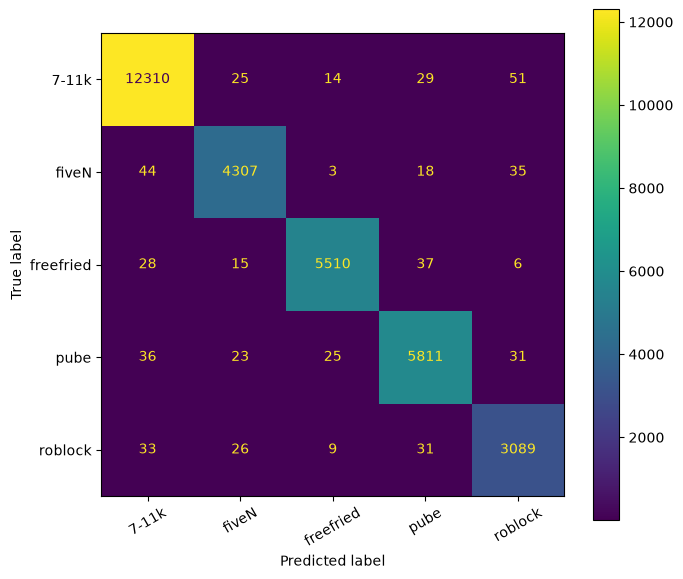

In [6]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay
for name in [BASELINE,SELECTED]:
    print(name)
    print(classification_report(base.true,probs[name].argmax(1),labels=range(5),target_names=training.CLASS_NAMES,zero_division=0))
fig,ax=plt.subplots(figsize=(7,6))
ConfusionMatrixDisplay.from_predictions(base.true,probs[SELECTED].argmax(1),labels=range(5),display_labels=training.CLASS_NAMES,ax=ax,xticks_rotation=30)
plt.tight_layout();fig.savefig(OUT/'selected_confusion.png',dpi=120);plt.show()


## 7. Full-data refit หลัง validation

ฝึกเฉพาะสูตรที่เลือกด้วย recipe เดิม. หาก baseline ชนะจะข้ามการฝึก. model.pt มี architecture, class mapping และ state_dict; load_model โหลดกลับโดยไม่ดาวน์โหลด pretrained weights.

In [7]:
full_paths={}
if RUN_FULL_REFIT:
    for name in selection['members']:
        full_paths[name]=training.fit_fixed(RAW,groups,training.RECIPES[name],OUT/name/'full',BATCH_SIZE,NUM_WORKERS)
else:print('ข้าม refit และ export: ตั้ง RUN_FULL_REFIT=True เมื่อต้องการผล test')


full epoch 1 / 18 loss 0.61767 seconds 181.8
full epoch 2 / 18 loss 0.36552 seconds 181.0
full epoch 3 / 18 loss 0.26153 seconds 180.6
full epoch 4 / 18 loss 0.21761 seconds 181.0
full epoch 5 / 18 loss 0.18146 seconds 180.9
full epoch 6 / 18 loss 0.16462 seconds 181.0
full epoch 7 / 18 loss 0.14436 seconds 180.9
full epoch 8 / 18 loss 0.12563 seconds 181.2
full epoch 9 / 18 loss 0.10586 seconds 181.0
full epoch 10 / 18 loss 0.09509 seconds 181.2
full epoch 11 / 18 loss 0.08474 seconds 182.1
full epoch 12 / 18 loss 0.07041 seconds 177.2
full epoch 13 / 18 loss 0.06117 seconds 173.8
full epoch 14 / 18 loss 0.05212 seconds 173.3
full epoch 15 / 18 loss 0.04726 seconds 173.5
full epoch 16 / 18 loss 0.04282 seconds 172.8
full epoch 17 / 18 loss 0.04259 seconds 173.6
full epoch 18 / 18 loss 0.04127 seconds 174.5
full epoch 1 / 18 loss 0.56824 seconds 173.5
full epoch 2 / 18 loss 0.31986 seconds 173.2
full epoch 3 / 18 loss 0.2364 seconds 178.0
full epoch 4 / 18 loss 0.19316 seconds 178.4
fu

## 8. Test inference & submission

คง ID/Task1–3/Task5 ทุกค่า จากฐาน 0.79963. เปลี่ยนเฉพาะ Task4 หากสูตรใหม่ผ่าน. ไม่ submit อัตโนมัติ. ถ้า baseline ชนะไม่สร้างไฟล์ซ้ำที่คำตอบเหมือนเดิม.

In [8]:
if RUN_FULL_REFIT and SELECTED!=BASELINE:
    test=pd.read_csv(RAW/'test.csv')
    assert test.id.is_unique and test.label.isna().all()
    views=training.TTA_VIEWS if selection['mode']=='tta' else ('identity',)
    members=[]
    for name,path in full_paths.items():
        cache=OUT/f'{name}_test_{selection["mode"]}.parquet'
        signature={'checkpoint_sha256':sha(path),'test_manifest_sha256':sha(RAW/'test.csv'),'views':list(views)}
        meta=cache.with_suffix('.json')
        if cache.exists():
            assert meta.exists() and json.loads(meta.read_text())==signature
            saved=pd.read_parquet(cache);assert saved.id.tolist()==test.id.tolist()
            p=saved[[f'p_{c}' for c in range(5)]].to_numpy()
        else:
            model=training.load_model(path)
            v=training.predict_views(model,RAW,test,'test',BATCH_SIZE,NUM_WORKERS,views)
            p=np.mean(list(v.values()),axis=0)
            saved=pd.DataFrame(p,columns=[f'p_{c}' for c in range(5)]);saved.insert(0,'id',test.id)
            saved.to_parquet(cache,index=False);meta.write_text(json.dumps(signature,indent=2))
            del model;gc.collect()
            if training.get_device().type=='mps':torch.mps.empty_cache()
            if training.get_device().type=='cuda':torch.cuda.empty_cache()
        assert p.shape==(len(test),5) and np.isfinite(p).all() and np.allclose(p.sum(1),1,atol=1e-5)
        members.append(p)
    final=np.mean(members,axis=0)
    predictions=pd.DataFrame({'id':test.id,'task4':final.argmax(1)})
    predictions.to_parquet(OUT/'task4_predictions.parquet',index=False)
    assert sha(BASE_SUBMISSION)==BASE_SUBMISSION_SHA
    with BASE_SUBMISSION.open(newline='') as f:source=list(csv.reader(f))
    assert source[0]==['id','task1','task2','task3','task4','task5']
    assert len(source)-1==len(test) and len(test)==25889
    # Align actual Test IDs with the combined submission, never assume position.
    assert test.id.tolist()==[r[0] for r in source[1:]]
    assert [r[0] for r in source[1:]]==[f'ANS{i+1:05d}' for i in range(len(test))]
    output=[r.copy() for r in source]
    for row,value in zip(output[1:],predictions.task4):row[4]=str(int(value))
    assert all(a[:4]+a[5:]==b[:4]+b[5:] for a,b in zip(source,output))
    destination=ROOT/'submission'/f'kaggle_t12345_t4_{RUN_NAME}_t5_directional_gap_cut_v1.csv'
    import io
    stream=io.StringIO(newline='');csv.writer(stream).writerows(output);text=stream.getvalue()
    if destination.exists():
        with destination.open(newline='') as f:assert list(csv.reader(f))==output,'Refuse overwrite of differing file'
    else:
        with destination.open('x',newline='') as f:f.write(text)
    with destination.open(newline='') as f:assert list(csv.reader(f))==output
    card={'selected':SELECTED,'base_sha256':BASE_SUBMISSION_SHA,'output_sha256':sha(destination),'rows':len(test),'Task5_base_public_overall':.79963,'kaggle_submitted':False}
    destination.with_suffix('.json').write_text(json.dumps(card,indent=2))
    print('Submission:',destination)
elif SELECTED==BASELINE:
    print('สูตรใหม่ไม่ผ่านเกณฑ์: ใช้ไฟล์เดิม',BASE_SUBMISSION)


Submission: /Users/meng/dev/MyUniversity/CPE342-MachineLearning/CPE342-Kaggle/submission/kaggle_t12345_t4_heavy_balance_v1_t5_directional_gap_cut_v1.csv


## 9. Resume และอ้างอิง

หยุด cell แล้วรอหยุดก่อน restart kernel. Run All ใหม่จะอ่าน model.pt/oof.parquet ของ folds ที่เสร็จ และ resume.pt ของ fold ที่ค้าง. ต้องใช้ run name, source และ settings เดิม. อาจมีความต่างเชิงตัวเลขข้าม hardware/software; ไม่รับประกัน bitwise GPU determinism. ไฟล์เก่าไม่ถูกแก้.

[torchvision transforms](https://docs.pytorch.org/vision/stable/transforms.html), [Random Erasing](https://docs.pytorch.org/vision/stable/generated/torchvision.transforms.RandomErasing.html). Augmentation เป็น standard methods; ความแรงและส่วนผสมนี้เป็น hypothesis ที่ต้องวัดด้วย validation ไม่ใช่ข้อมูลยืนยันสูตรของทีมอื่น.